# Planificación de velocidad y trayectoria para un agente de IA en Tocancipá

**Física A: Hardware e Información · Proyecto final**

**Integrantes:** John Edward Rincón Aragón (202420895) · Samuel Zuluaga (202520012) · Samuel Eduardo Beltrán López (202522601)

**Pregunta de investigación.** ¿Hasta qué punto un modelo físico reducido puede estimar trayectorias, velocidades y distancias de frenado suficientemente precisas para que un agente de IA complete vueltas rápidas y válidas en Tocancipá dentro de Assetto Corsa?

**Pregunta física auxiliar.** ¿Cómo depende la distancia de pista que el modelo necesita conocer hacia adelante (visibilidad $D_v$) de la velocidad inicial $v_0$, del radio de la curva $R$ y del coeficiente de fricción $\mu$?

**Cómo leer este notebook.** Cada bloque de código va precedido de una explicación de qué hace y por qué, y seguido de la interpretación de su resultado. Las secciones siguen este orden: contexto → modelo físico → método numérico → validación → aplicación a Tocancipá → comparación con Assetto Corsa → limitaciones → conclusiones → declaración de uso de IA.

## Contenido

1. Contexto: el problema, Assetto Corsa y la conexión con ISC
2. Modelo físico: aspectos considerados, ecuaciones, simplificaciones y fenómenos omitidos
3. Método numérico: pista discreta, perfil de velocidad, integración en el tiempo y huella del auto
4. Validación con casos analíticos y convergencia con $\Delta t$
5. Respuesta a la pregunta física: visibilidad necesaria según $v_0$, $R$ y $\mu$
6. Trayectoria optimizada frente a la línea central
7. Aplicación a Tocancipá
8. Comparación con Assetto Corsa y con el agente
9. Limitaciones
10. Conclusiones
11. Declaración de uso de IA
12. Referencias

### Librerías necesarias

El notebook usa solo NumPy, SciPy y Matplotlib. Si falta alguna, se instala con:

```
pip install numpy scipy matplotlib
```

Los datos externos (geometría de Tocancipá y telemetría de Assetto Corsa) van en la carpeta `datos/`. Si un archivo no existe, la celda correspondiente lo avisa y usa una pista de prueba, para que el notebook se ejecute de principio a fin sin errores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "font.size": 11})
DATOS = Path("datos")
G = 9.81  # m/s^2

## 1. Contexto

### 1.1 El problema

Nuestro proyecto planifica la trayectoria y la velocidad de un vehículo usando solo el tramo de pista que tiene por delante. Buscamos calcular por dónde le conviene pasar, cuánto puede acelerar y cuándo necesita frenar para tomar las curvas sin salirse. La geometría de la trayectoria determina cuánto hay que girar; la velocidad determina qué tan exigente es hacerlo.

El modelo físico no maneja el auto: produce una **trayectoria de referencia** y un **perfil de velocidad** que un agente de IA con capacidad básica de conducción usa como información para decidir cuánto acelerar, frenar o girar. Por eso distinguimos tres cosas: lo que recomienda el modelo, lo que pide el agente y lo que realmente hace el auto en el simulador.

### 1.2 Assetto Corsa y Tocancipá

Assetto Corsa es un simulador de carreras desarrollado por Kunos Simulazioni, un estudio italiano, y lanzado para PC en diciembre de 2014. Su motor de física simula con detalle los neumáticos (temperatura, desgaste y puntos planos), la suspensión y la aerodinámica, y sus pistas oficiales fueron reproducidas con escaneo láser. Además, admite contenido creado por la comunidad: el Autódromo de Tocancipá no es una pista oficial, sino un mod hecho desde cero para la Asociación de Pilotos Virtuales Sudamericanos (APVS). El simulador también se ha usado en investigación de conducción autónoma (por ejemplo, la plataforma Assetto Corsa Gym, de 2024), porque permite leer en tiempo real el estado del vehículo y enviarle controles, que es justo lo que necesita nuestro agente.

En cuanto al realismo, el juego trae perfiles de ayudas (Gamer, Racer, Pro y uno personalizado) que van desde ayudas artificiales hasta ayudas de fábrica o ninguna. Usaremos la configuración más exigente que permita el simulador, con la caja automática y las mismas ayudas en todas las pruebas. En ese modo, Assetto Corsa modela fenómenos que nosotros omitimos, como la transferencia de peso, los neumáticos reales y la aerodinámica, así que lo usamos como una referencia más detallada para medir los errores de nuestro modelo. Aun así, sigue siendo un modelo y no un auto real: la precisión de la pista depende del autor del mod, y un buen resultado en el simulador no demuestra por sí solo validez en la vida real. Un dato que respalda nuestra simplificación en 2D es que el circuito real mide unos 2,72 km, tiene 14 curvas y un desnivel de solo unos 9 m.

> ✍️ **Por escribir:** **1.3 Conexión con Ingeniería de Sistemas y Computación.** El profesor pidió dejarla clara. Ideas para desarrollar en un párrafo:

- Un agente de IA que conduce necesita un **modelo del mundo** barato de calcular: nuestro modelo físico reducido cumple ese papel y debe correr más rápido que el tiempo real.
- El problema es de **planificación bajo información limitada** (horizonte $D_v$), igual que en robótica móvil y vehículos autónomos.
- Hay un compromiso entre **precisión y costo computacional**: el paso $\Delta t$ y la resolución de la pista (1 m) fijan cuántas operaciones hacemos por segundo simulado.
- La función de recompensa y la comparación con/sin modelo conectan la física con el **aprendizaje por refuerzo**.

## 2. Modelo físico

### 2.1 Aspectos que consideramos y por qué


**Masa del vehículo.** La incluimos porque relaciona fuerza y aceleración (F = m·a). Cuando el agarre es el límite, la masa se cancela: a_max = μg. Por eso, en nuestro modelo la distancia de frenado y la velocidad en curva no dependen de la masa. Sí importa cuando el límite es la potencia del motor, porque un auto más pesado acelera más lento en recta.

**Potencia útil del motor.** A alta velocidad, la fuerza de tracción disponible es F = P/v. Por eso la aceleración cae a medida que el auto va más rápido (a = P/(m·v)). Con ella el modelo distingue la salida de una curva, donde manda el agarre, del final de una recta, donde manda el motor, y estima mejor cuánta velocidad se gana antes de la siguiente frenada.

**Aceleración máxima.** Es el tope de aceleración longitudinal, sea por agarre o por motor. Sin ella, el perfil de velocidad podría subir de forma irreal entre curvas. Con ella, el tiempo estimado en cada recta tiene sentido físico.

**Frenado máximo.** Es la variable central de nuestra pregunta. Con una desaceleración máxima a_f, la distancia para bajar de v₀ a la velocidad de la curva v_c es d = (v₀² − v_c²) / (2·a_f). Si a_f está mal estimada, el agente frena tarde y se sale, o frena antes de tiempo y pierde tiempo.

**Fricción entre neumáticos y carretera.** El coeficiente μ (del orden de 0,8 a 1,0 en asfalto seco) limita la aceleración lateral a μg. De ahí sale la velocidad máxima en una curva de radio R: v_max = √(μ·g·R). También limita el frenado, así que con menos fricción baja la velocidad en curva y se alarga la distancia de frenado.

**Velocidad y posición.** Son las variables de estado que el método numérico actualiza en cada paso. Con ellas sabemos dónde está el auto respecto a la pista y comparamos lo que predice el modelo con lo que pasa en Assetto Corsa.

**Orientación.** El ángulo ψ dice hacia dónde apunta el auto, y por tanto hacia dónde avanza: dx/dt = v·cos ψ, dy/dt = v·sin ψ. Sin ψ no podríamos convertir la velocidad en movimiento sobre el plano ni saber si el auto va alineado con la pista.

**Giro del volante y relación de dirección.** El agente controla el volante, pero el modelo necesita el ángulo de las ruedas: δ = θ_volante / relación de dirección. Con ella traducimos lo que recomienda el modelo en comandos que el agente puede ejecutar. Por ejemplo, con una relación 15:1, un giro de 3° en las ruedas equivale a unos 45° de volante.

**Distancia entre ejes (para el modelo de bicicleta cinemático).** En el modelo de bicicleta cinemático, la distancia L fija cuánto gira el auto para un ángulo de ruedas dado: dψ/dt = (v/L)·tan δ, y el radio de giro es R = L / tan δ. Así podemos calcular el ángulo necesario para seguir una curva. Con L = 2,6 m y R = 50 m, δ ≈ 3°.

**Radio y curvatura de las curvas.** La curvatura κ = 1/R dice qué tan cerrada es una curva. La aceleración lateral que exige es a_lat = v²·κ. Por eso las curvas cerradas obligan a ir más lento, y la curvatura es lo que decide dónde y cuánto hay que frenar.

**Geometría de la pista y puntos de referencia cada metro.** Representamos la pista con puntos espaciados 1 m. De cada tres puntos seguidos sacamos la orientación y la curvatura local. Un metro es lo bastante fino para describir las curvas de Tocancipá sin que el cálculo se vuelva pesado. Además, esos puntos son los que después desplazamos para buscar trayectorias.

**Visibilidad (Explicar que por visibilidad tomamos una distancia límite para estimar el comportamiento del vehículo, por ejemplo: 100 m de visión equivalen a 100 m de pista estimable).** Atendiendo al comentario del profesor, no la tratamos como un campo de visión subjetivo. La definimos como una distancia límite D_v: el tramo de pista hacia adelante cuya geometría el modelo puede usar. Por ejemplo, 100 m de visibilidad equivalen a 100 m de pista estimable. Esto convierte la visibilidad en un parámetro medible y limita la velocidad segura: el auto debe poder bajar a la velocidad de una curva que aparezca al final del tramo visible, es decir, v ≤ √(v_c² + 2·a_f·D_v). Con a_f = 9 m/s² y D_v = 100 m, el auto puede detenerse por completo si no supera unos 42 m/s (≈150 km/h).

**Dimensiones del automóvil y de la pista.** El ancho de la pista menos el ancho del auto da el margen lateral real para mover la trayectoria, y el largo y el ancho del auto dicen cuándo una esquina toca el borde. Sin estos datos, el modelo propondría trayectorias que en el juego cuentan como salida de pista.

**Paso de tiempo.** Δt define cada cuánto actualizamos posición y velocidad, y de él depende la precisión. Por ejemplo, a 50 m/s con Δt = 0,05 s el auto avanza 2,5 m por paso, más que la separación de 1 m entre puntos, y podría saltarse el inicio de una curva o un contacto con el borde. Por eso variamos Δt en la validación y elegimos uno en el que los resultados ya no cambian al reducirlo.

### 2.2 Ecuaciones del modelo

**Estado del vehículo.** Posición $(x, y)$, orientación $\psi$ y rapidez $v$. Controles: ángulo de las ruedas delanteras $\delta$ y aceleración longitudinal $a$.

**Modelo de bicicleta cinemático** (referencia en el eje trasero, sin deslizamiento lateral):

$$\dot x = v\cos\psi,\qquad \dot y = v\sin\psi,\qquad \dot\psi = \frac{v}{L}\tan\delta,\qquad \dot v = a$$

Radio de giro para un ángulo $\delta$: $R = \dfrac{L}{\tan\delta}$. Ángulo del volante: $\theta_{volante} = r_{dir}\,\delta$.

**Límite de agarre (círculo de fricción).** La aceleración total no puede superar $\mu g$:

$$\sqrt{a^2 + a_{lat}^2} \le \mu g,\qquad a_{lat} = v^2\kappa = \frac{v^2}{R}$$

**Velocidad máxima en curva** (toda la fricción se usa para girar):

$$v_{max} = \sqrt{\mu g R}$$

**Aceleración por el motor.** Con potencia útil $P$, la fuerza de tracción es $F = P/v$, y la aceleración está limitada por el motor y por el agarre:

$$a_{motor} = \min\!\left(a_{acc,max},\ \frac{P}{m v}\right)$$

**Distancia de frenado** de $v_0$ a $v_c$ con desaceleración $a_f$:

$$d = \frac{v_0^2 - v_c^2}{2a_f}$$

**Condición de visibilidad.** Si el modelo solo conoce $D_v$ metros de pista hacia adelante, el auto debe poder bajar a la velocidad de una curva que aparezca al final de ese tramo:

$$v \le \sqrt{v_c^2 + 2a_f D_v}$$

En el caso más conservador ($v_c = 0$, detenerse), $v \le \sqrt{2a_f D_v}$.

**Visibilidad mínima para una curva** de radio $R$ cuando se llega a $v_0$ y el frenado está limitado por el agarre ($a_f = \mu g$):

$$D_{min} = \frac{v_0^2 - \mu g R}{2\mu g}\quad\text{si } v_0 > \sqrt{\mu g R},\qquad D_{min} = 0 \text{ en otro caso}$$

Esta última ecuación responde la pregunta física auxiliar: $D_{min}$ crece con $v_0^2$, baja linealmente con $R$ y, para un mismo $v_0$, baja aproximadamente como $1/\mu$.

> ✍️ **Por escribir:** explicar con palabras de dónde sale cada ecuación (por ejemplo, $d = (v_0^2 - v_c^2)/2a_f$ sale de la cinemática con aceleración constante, y $v_{max} = \sqrt{\mu g R}$ de igualar la fuerza centrípeta $m v^2/R$ con la fricción máxima $\mu m g$). En la sustentación pueden preguntar "¿qué pasa si eliminamos este término?".

### 2.3 Simplificaciones que elegimos y por qué


**Modelo de bicicleta cinemático (representamos el movimiento con una rueda delantera y otra trasera equivalentes, sin calcular por separado las cuatro ruedas).** Juntamos las dos ruedas de cada eje en una sola rueda equivalente y suponemos que no hay deslizamiento lateral. Así el giro depende solo de la geometría (v, δ y L) y necesitamos muy pocos parámetros. Funciona bien mientras el auto no se acerque al límite de agarre; por eso lo combinamos con los límites de fricción, que descartan las maniobras en las que esta suposición deja de valer.

**Huella rectangular (se conserva para representar las dimensiones del carro y detectar contactos o salidas de pista; no define su dinámica de giro).** El modelo de bicicleta trata al auto como una línea, así que podría dejar medio carro fuera de la pista sin notarlo. Por eso guardamos un rectángulo del tamaño del auto, girado según ψ, y revisamos sus esquinas contra los bordes. El rectángulo sirve para detectar contactos y salidas; no cambia cómo gira el auto.

**Movimiento en dos dimensiones (el sistema no considera pendientes en pista ni la altura del vehículo).** Trabajamos solo en el plano (x, y, ψ), sin alturas. Esto reduce mucho las ecuaciones y basta para estudiar trayectoria y frenado. Como consecuencia, no vemos el efecto de las pendientes: en una bajada, parte del peso empuja hacia adelante y la frenada efectiva es menor que μg.

**Dirección equivalente (las ruedas delanteras se representan con un único ángulo de dirección, sin considerar direcciones independientes).** En un auto real, la rueda delantera interior gira un poco más que la exterior. Nosotros usamos un único ángulo δ, coherente con el modelo de bicicleta. El error es pequeño salvo en curvas muy cerradas, y nos ahorra modelar la geometría de la dirección.

**Capacidades máximas resumidas.** En lugar de curvas de torque contra revoluciones o mapas de frenos, resumimos el auto en unos pocos valores: potencia útil, aceleración máxima y frenado máximo. Estos valores se pueden medir directamente en Assetto Corsa (por ejemplo, tiempo de 0 a 100 km/h o distancia de frenado desde 100 km/h). Calibrar es sencillo, aunque perdemos las variaciones de cada marcha.

**Fricción simplificada (empleamos un límite global de aceleración lateral y longitudinal, sin modelar el deslizamiento de cada neumático).** Usamos un límite global de aceleración: la combinación de aceleración lateral y longitudinal no puede superar μg (círculo de fricción), sin modelar el deslizamiento de cada neumático. Así el modelo sabe que no se puede frenar a fondo y girar al máximo al mismo tiempo. No reproduce el comportamiento detallado de un neumático real cerca del límite.

**Curvas ideales para validar (validaremos inicialmente con curvas circulares de radio constante; la geometría de Tocancipá se representará mediante aproximaciones locales).** Empezamos con curvas circulares de radio constante porque tienen solución analítica (v_max = √(μgR) y la fórmula de distancia de frenado), así podemos medir el error numérico exacto. Para Tocancipá aproximamos cada tramo por el círculo que mejor ajusta tres puntos seguidos. Validamos primero donde conocemos la respuesta y luego pasamos a la pista real.

**Trayectoria por puntos desplazables (partimos de puntos centrales y permitimos moverlos lateralmente dentro de los límites de pista para comparar trayectorias).** Partimos de los puntos centrales y dejamos que cada uno se mueva hacia los lados, dentro del margen que permiten las dimensiones del auto y de la pista. Una trayectoria más abierta tiene menor curvatura y permite más velocidad. Al comparar trayectorias por su tiempo estimado, el punto de apex sale del cálculo en vez de imponerse desde el inicio.

**Actualización por intervalos pequeños (aproxima el movimiento continuo).** El movimiento real es continuo, pero el computador lo calcula en pasos: v(k+1) = v(k) + a·Δt y x(k+1) = x(k) + v·cos ψ·Δt (igual para y). Si Δt es pequeño, la aproximación se acerca a la solución continua. Lo comprobamos en la validación reduciendo Δt y verificando que los resultados converjan.

### 2.4 Fenómenos importantes que omitimos y por qué


**Ruedas independientes.** Modelar cada rueda exige calcular cuatro fuerzas de contacto distintas y conocer su reparto. Al agruparlas por eje perdemos efectos asimétricos, como que la rueda interior pierda carga en curva, pero conservamos lo que importa para estimar trayectoria y velocidad.

**Rotación e inercia de las ruedas.** Para acelerar el auto también hay que hacer girar más rápido las ruedas, y frenar fuerte puede bloquearlas. Omitirlo hace la aceleración un poco optimista y deja fuera el bloqueo. A cambio no necesitamos momentos de inercia que no podemos medir.

**Ejes motrices y diferencial.** Cuál eje empuja y cómo reparte la fuerza el diferencial influye en la tracción a la salida de las curvas. No lo modelamos porque necesita datos internos del auto. En consecuencia, el modelo no distingue entre un auto que tiende a abrirse o a cerrarse al acelerar en curva.

**Transferencia de peso.** Al frenar, parte del peso pasa al eje delantero (para un auto típico, cerca del 18 % del peso en una frenada fuerte), y eso cambia el agarre de cada eje. Modelarlo exige la altura del centro de masa y la suspensión. Con un μ constante, el agarre total se mantiene, pero los neumáticos reales pierden algo de agarre con más carga, así que el modelo puede ser algo optimista.

**Suspensión.** Su efecto aparece como oscilaciones rápidas de carga y altura, sobre todo en baches y cambios bruscos. Necesitaría constantes de resorte y amortiguación que no tenemos. En una pista plana, con maniobras suaves, su influencia sobre la trayectoria y el frenado es pequeña.

**Balanceo del coche (es decir, no consideramos que se pueda volcar).** Un auto de calle típico solo volcaría con una aceleración lateral cercana a 1,4 g (ancho de vía / (2·altura del centro de masa)), pero el agarre lo limita a cerca de 1 g, así que en asfalto el auto desliza antes de volcarse.

**Dinámica detallada de rotación.** En el modelo cinemático, la velocidad de giro sale directamente de la geometría y no de los momentos de fuerza ni de la inercia de giro del auto. Por eso no hay retraso entre girar el volante y que el auto gire. A velocidades moderadas el error es pequeño, y nos evita parámetros difíciles de obtener.

**Neumáticos reales.** Un neumático real depende del ángulo de deslizamiento, la carga y la temperatura, y se describe con curvas de muchos parámetros. Los reemplazamos por un único μ. Esto basta para estimar límites de velocidad y frenado, pero no el comportamiento fino cerca del límite.

**Derrapes (el modelo cinemático no los reproduce; los límites de adherencia sirven para descartar maniobras inviables).** El modelo cinemático supone que las ruedas no deslizan, así que no puede reproducir un derrape ni su recuperación. Usamos los límites de adherencia para descartar las maniobras que lo provocarían. El modelo recomienda maniobras dentro del agarre disponible, y el agente debe evitar los derrapes en lugar de corregirlos.

**Caja de cambios y funcionamiento del motor (las pruebas se realizarán con el vehículo en modo automático en el simulador).** Usamos una potencia útil constante y dejamos el auto en modo automático en el simulador, para que las marchas no dependan del agente. Así no modelamos los cambios ni la curva del motor, aunque perdemos las caídas de aceleración durante los cambios de marcha.

**Ayudas electrónicas (no modelamos ninguna ayuda que pueda tener el vehículo, ejemplo: frenos ABS, etc.).** Mantendremos la misma configuración de ayudas en todas las pruebas y mediremos el frenado y la aceleración máximos con ella, de modo que su efecto quede incluido en los valores calibrados y no en ecuaciones aparte.

**Aerodinámica.** El arrastre es F = ½·ρ·C_d·A·v². Para un auto típico a 50 m/s son unos 1.000 N, cerca de 0,8 m/s², frente a una frenada de unos 9 m/s². Omitirlo sobreestima un poco la velocidad en recta y alarga algo la distancia de frenado estimada, lo cual queda del lado seguro. Tampoco consideramos la carga aerodinámica, que aumenta el agarre a alta velocidad.

**Pendientes y peraltes.** Como trabajamos en 2D, no hay inclinación. Un peralte permitiría más velocidad en curva y una pendiente cambiaría la frenada efectiva. Donde la pista los tenga, estas serán fuentes de diferencia entre lo que predice el modelo y lo que ocurre en el juego, y las analizaremos así.

**Irregularidades del suelo.** Son pequeñas, variables y difíciles de medir, y afectan sobre todo al contacto instantáneo del neumático. Omitirlas no cambia la trayectoria a gran escala y mantiene el modelo determinista y reproducible.

**Clima y evolución del agarre (se simplifica solo con la fricción).** En el simulador fijamos las mismas condiciones en todas las pruebas, así que resumimos el estado de la pista en un μ constante. El modelo no se adapta a lluvia, temperatura o desgaste de neumáticos.

**Daños y deformación en choques (detectamos los contactos y detenemos la simulación; no estimamos gravedad del choque).** Cuando la huella del auto toca un borde u obstáculo, detenemos la simulación y lo registramos como contacto, sin estimar qué tan grave fue. El objetivo es evitar los choques, no describirlos. El contacto se usa como penalización en la función de recompensa y como criterio de vuelta inválida.

### 2.5 Parámetros

Agrupamos todos los parámetros en un diccionario para cambiarlos en un solo lugar. **Los valores son provisionales:** hay que reemplazarlos por los del auto elegido en Assetto Corsa (masa y potencia de la ficha del auto; frenado y aceleración medidos en el simulador, por ejemplo con la distancia de frenado desde 100 km/h).

In [2]:
P = dict(
    m=1300.0,          # masa [kg]                         -> ficha del auto en AC
    P_util=110e3,      # potencia útil [W]                 -> ficha del auto en AC
    mu=0.9,            # coeficiente de fricción [-]       -> calibrar con v_max en curva
    a_acc_max=5.0,     # aceleración máxima [m/s^2]        -> medir 0-100 km/h en AC
    a_fre_max=0.9*G,   # frenado máximo [m/s^2]            -> medir frenado 100-0 en AC
    v_tope=60.0,       # velocidad máxima [m/s]
    L=2.6,             # distancia entre ejes [m]
    largo=4.3,         # largo del auto [m]
    ancho=1.8,         # ancho del auto [m]
    r_dir=15.0,        # relación de dirección [-]
    ancho_pista=11.0,  # ancho de la pista [m]
    margen=0.3,        # margen de seguridad a cada borde [m]
    D_v=100.0,         # visibilidad: pista conocida hacia adelante [m]
    ds=1.0,            # separación entre puntos de la pista [m]
    dt=0.01,           # paso de tiempo [s]
)
print(f"v_max en curva de R = 50 m: {np.sqrt(P['mu']*G*50):.1f} m/s")
print(f"Velocidad segura sin ver curvas (D_v = {P['D_v']:.0f} m): {np.sqrt(2*P['a_fre_max']*P['D_v']):.1f} m/s")

v_max en curva de R = 50 m: 21.0 m/s
Velocidad segura sin ver curvas (D_v = 100 m): 42.0 m/s


> ✍️ **Por escribir:** interpretar los dos números impresos (por ejemplo, qué significa que la visibilidad limite la velocidad en recta).

## 3. Método numérico

### 3.1 Fórmulas analíticas

Estas funciones implementan directamente las ecuaciones de la sección 2.2. Las usamos como referencia exacta para validar la simulación numérica.

In [3]:
def v_max_curva(R, mu=P["mu"]):
    # v_max = sqrt(mu g R)
    return np.sqrt(mu * G * np.abs(R))

def distancia_frenado(v0, vc, a_f):
    # d = (v0^2 - vc^2) / (2 a_f); cero si no hace falta frenar
    return np.maximum(v0**2 - vc**2, 0.0) / (2 * a_f)

def v_max_visibilidad(vc, a_f, D_v):
    # v <= sqrt(vc^2 + 2 a_f D_v)
    return np.sqrt(vc**2 + 2 * a_f * D_v)

def visibilidad_minima(v0, R, mu):
    # D_min = (v0^2 - mu g R) / (2 mu g), con frenado limitado por agarre
    return np.maximum(v0**2 - mu * G * R, 0.0) / (2 * mu * G)

### 3.2 La pista como puntos cada metro

Representamos la línea central de la pista con puntos separados $\Delta s = 1$ m. La curvatura local sale de cada tres puntos seguidos con la fórmula de Menger: si $A$ es el área del triángulo que forman y $a, b, c$ sus lados,

$$\kappa = \frac{4A}{abc}$$

El signo de $\kappa$ indica si la curva va a la izquierda (positivo) o a la derecha (negativo).

Mientras no tengamos la geometría de Tocancipá usamos una **pista de prueba**: recta, curva circular de radio conocido y recta. Como el radio es conocido, sirve para validar.

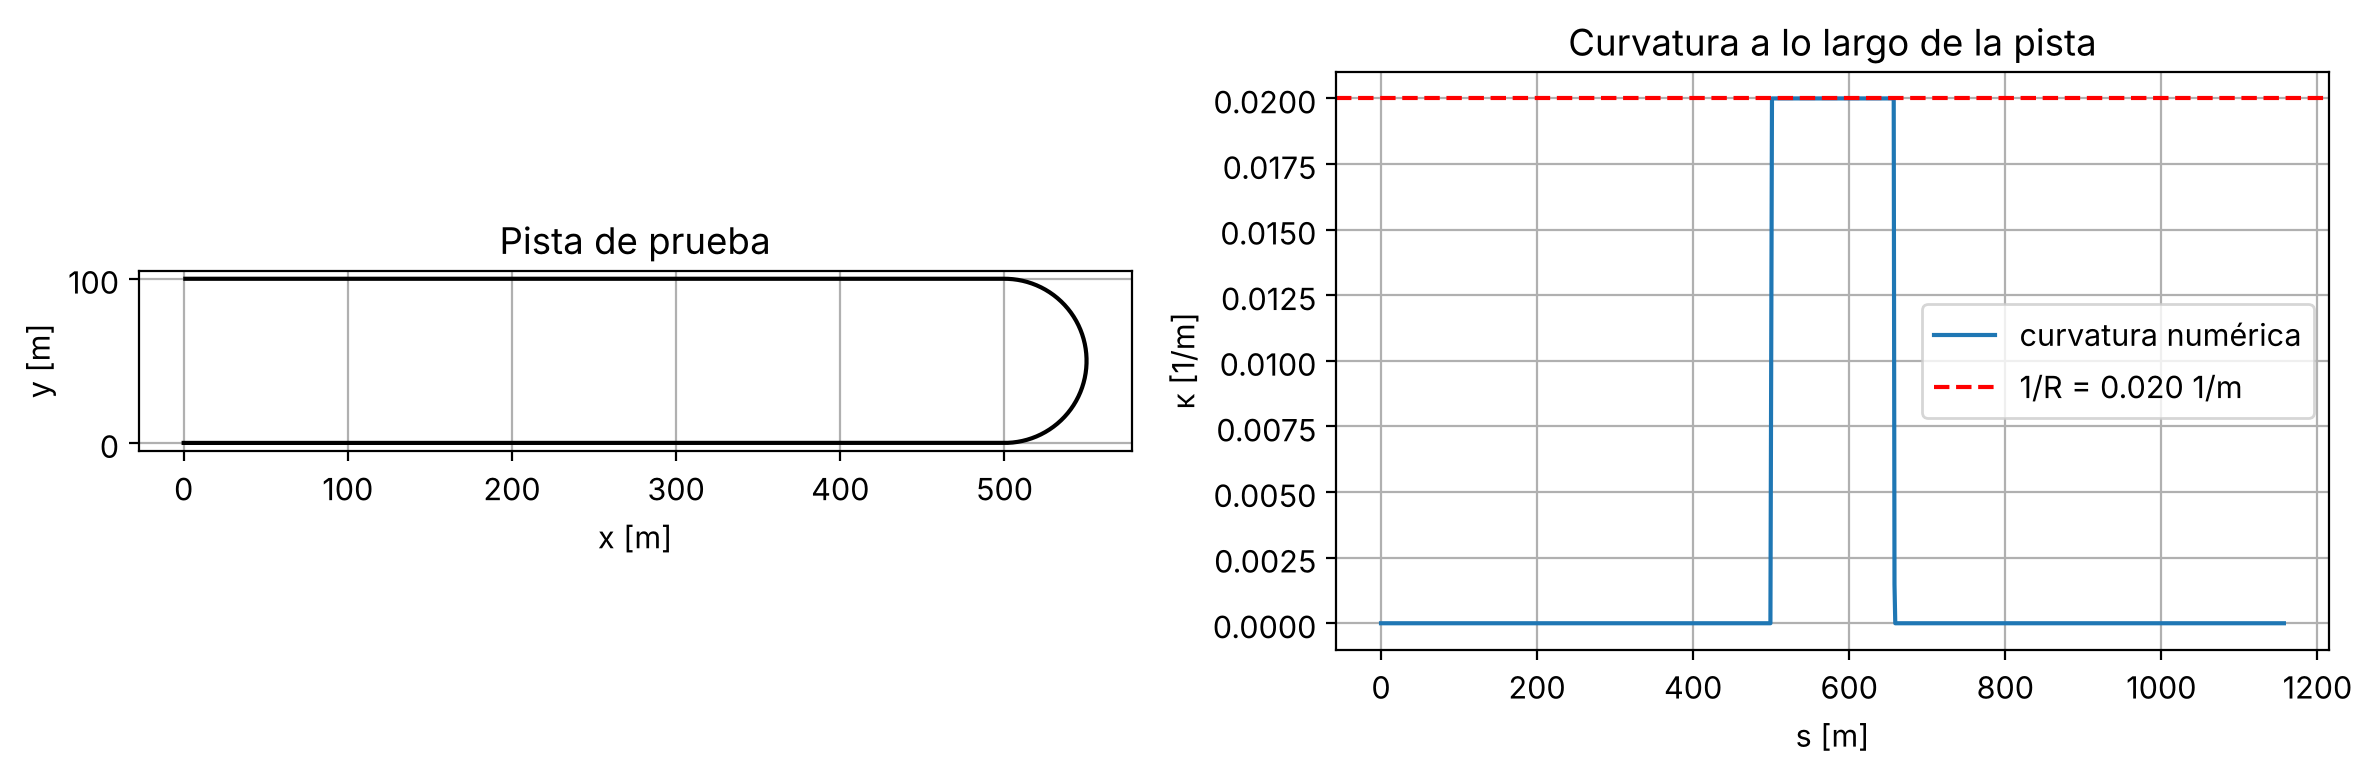

In [4]:
def remuestrear(x, y, ds=P["ds"]):
    # Reparte puntos a distancia constante ds a lo largo de la curva
    d = np.hypot(np.diff(x), np.diff(y))
    s = np.concatenate([[0.0], np.cumsum(d)])
    s_nuevo = np.arange(0.0, s[-1], ds)
    return np.interp(s_nuevo, s, x), np.interp(s_nuevo, s, y)

def curvatura(x, y):
    # Curvatura con signo a partir de tres puntos seguidos (Menger)
    k = np.zeros_like(x)
    ax, ay, bx, by, cx, cy = x[:-2], y[:-2], x[1:-1], y[1:-1], x[2:], y[2:]
    cruz = (bx - ax) * (cy - ay) - (by - ay) * (cx - ax)   # = 2A con signo
    a, b, c = np.hypot(bx - ax, by - ay), np.hypot(cx - bx, cy - by), np.hypot(cx - ax, cy - ay)
    k[1:-1] = 2 * cruz / (a * b * c)
    k[0], k[-1] = k[1], k[-2]
    return k

def pista_prueba(L_recta=500.0, R=50.0, angulo=np.pi, ds=P["ds"]):
    # Recta + arco circular de radio R + recta, con puntos cada ds
    s1 = np.arange(0.0, L_recta, ds)
    th = np.arange(0.0, angulo, ds / R)
    x0, y0 = L_recta + R * np.sin(angulo), R * (1 - np.cos(angulo))
    x = np.concatenate([s1, L_recta + R * np.sin(th), x0 + s1 * np.cos(angulo)])
    y = np.concatenate([0 * s1, R * (1 - np.cos(th)), y0 + s1 * np.sin(angulo)])
    return x, y

R_PRUEBA = 50.0
xc, yc = pista_prueba(R=R_PRUEBA)
kc = curvatura(xc, yc)
s = np.arange(len(xc)) * P["ds"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(xc, yc, "k-"); a1.set_aspect("equal"); a1.set(xlabel="x [m]", ylabel="y [m]", title="Pista de prueba")
a2.plot(s, kc, label="curvatura numérica")
a2.axhline(1 / R_PRUEBA, ls="--", c="r", label=f"1/R = {1/R_PRUEBA:.3f} 1/m")
a2.set(xlabel="s [m]", ylabel="κ [1/m]", title="Curvatura a lo largo de la pista"); a2.legend()
plt.tight_layout(); plt.show()

> ✍️ **Por escribir:** interpretar: la curvatura numérica en el arco coincide con $1/R$. Comentar el salto en las uniones recta-curva (la curvatura cambia de golpe, cosa que en una pista real no pasa porque hay curvas de transición).

### 3.3 Perfil de velocidad

El perfil de velocidad es la velocidad máxima que el modelo recomienda en cada punto de la pista. Se calcula en tres pasos:

1. **Límite por curvatura:** $v_{lim} = \min\left(\sqrt{\mu g/|\kappa|},\ v_{tope}\right)$.
2. **Límite por visibilidad:** en cada punto solo se consideran las curvas dentro de los siguientes $D_v$ metros, y se exige poder detenerse al final de ese tramo: $v_i \le \sqrt{v_{lim,j}^2 + 2a_f(s_j - s_i)}$ para todo $j$ visible, y $v_i \le \sqrt{2a_f D_v}$.
3. **Pasadas hacia atrás y hacia adelante:** hacia atrás se verifica que siempre se pueda frenar a tiempo; hacia adelante, que el motor y el agarre permitan acelerar hasta esa velocidad. En ambas se usa el agarre que sobra después de girar: $a_{disp} = \sqrt{(\mu g)^2 - a_{lat}^2}$.

Las pasadas usan la relación $v_{i+1}^2 = v_i^2 + 2a\,\Delta s$, que es exacta para aceleración constante en cada tramo de 1 m.

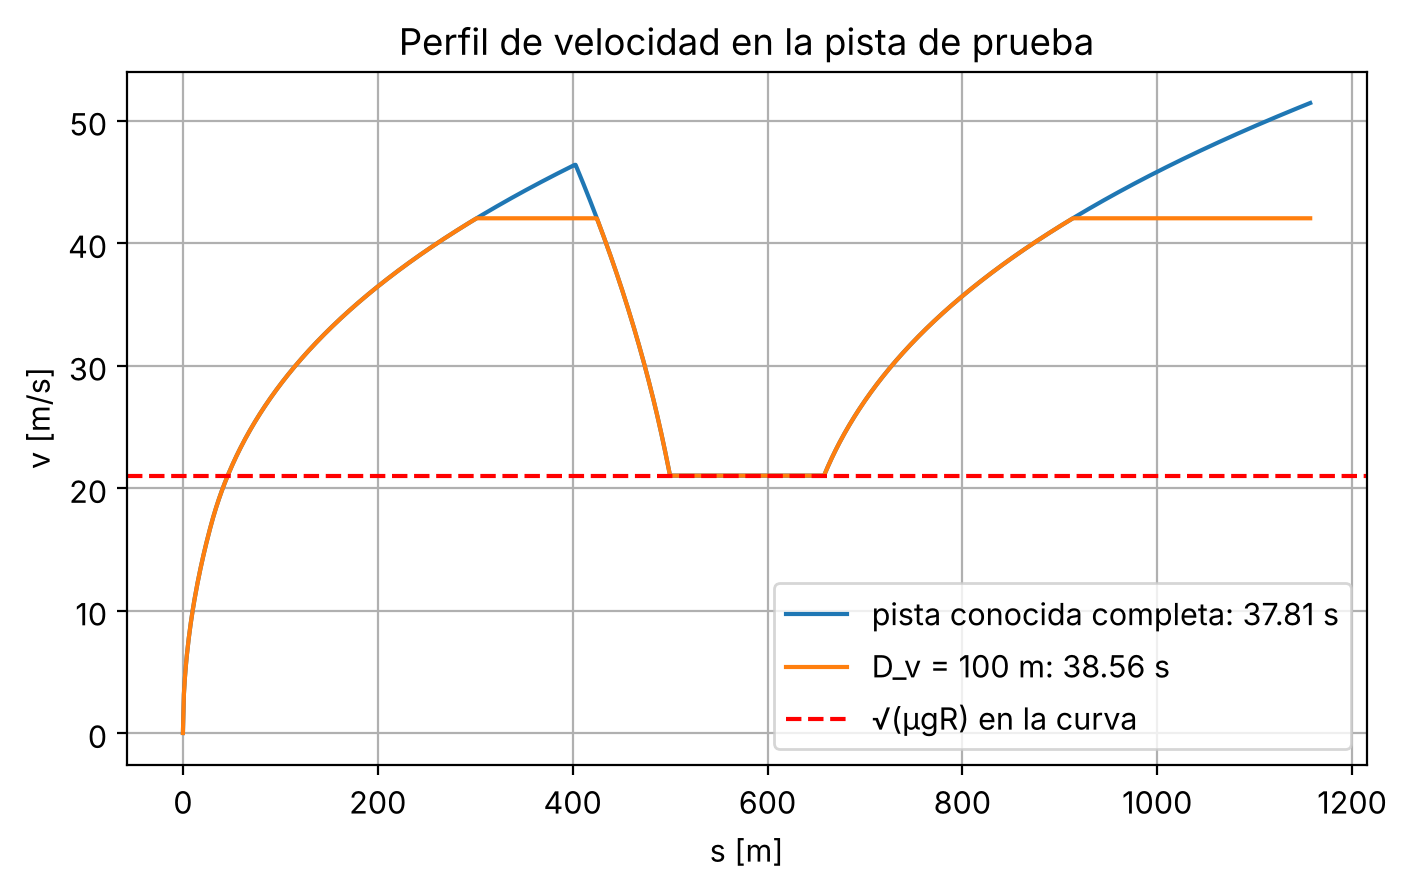

In [5]:
def perfil_velocidad(k, p=P, visibilidad=None, v_inicial=0.0):
    N, ds, mu_g, a_f = len(k), p["ds"], p["mu"] * G, p["a_fre_max"]
    v_lim = np.minimum(np.sqrt(mu_g / np.maximum(np.abs(k), 1e-9)), p["v_tope"])

    tope = v_lim.copy()
    if visibilidad is not None:                       # paso 2: solo D_v metros conocidos
        W = int(visibilidad / ds)
        relleno = np.concatenate([v_lim, np.full(W, np.inf)])
        ventanas = np.lib.stride_tricks.sliding_window_view(relleno, W)[:N]
        dist = np.arange(W) * ds
        tope = np.minimum(tope, np.sqrt(ventanas**2 + 2 * a_f * dist).min(axis=1))
        tope = np.minimum(tope, np.sqrt(2 * a_f * visibilidad))   # poder detenerse al final de lo visible

    v = tope.copy()
    for i in range(N - 2, -1, -1):                    # paso 3a: hacia atrás (frenado)
        a_disp = min(a_f, np.sqrt(max(mu_g**2 - (v[i + 1]**2 * abs(k[i + 1]))**2, 0.0)))
        v[i] = min(v[i], np.sqrt(v[i + 1]**2 + 2 * a_disp * ds))
    v[0] = min(v[0], v_inicial)
    for i in range(N - 1):                            # paso 3b: hacia adelante (motor + agarre)
        a_mot = min(p["a_acc_max"], p["P_util"] / (p["m"] * max(v[i], 1.0)))
        a_disp = np.sqrt(max(mu_g**2 - (v[i]**2 * abs(k[i]))**2, 0.0))
        v[i + 1] = min(v[i + 1], np.sqrt(v[i]**2 + 2 * min(a_mot, a_disp) * ds))
    return v

def tiempo_recorrido(v, ds=P["ds"]):
    # t = suma de ds / velocidad media de cada tramo
    return np.sum(2 * ds / (v[:-1] + v[1:]))

v_sin_vis = perfil_velocidad(kc, visibilidad=None)
v_con_vis = perfil_velocidad(kc, visibilidad=P["D_v"])

plt.plot(s, v_sin_vis, label=f"pista conocida completa: {tiempo_recorrido(v_sin_vis):.2f} s")
plt.plot(s, v_con_vis, label=f"D_v = {P['D_v']:.0f} m: {tiempo_recorrido(v_con_vis):.2f} s")
plt.axhline(v_max_curva(R_PRUEBA), ls="--", c="r", label="√(μgR) en la curva")
plt.xlabel("s [m]"); plt.ylabel("v [m/s]"); plt.title("Perfil de velocidad en la pista de prueba"); plt.legend()
plt.show()

> ✍️ **Por escribir:** interpretar: dónde empieza a frenar el perfil, por qué en la curva vale $\sqrt{\mu g R}$, por qué la curva de aceleración se aplana (potencia) y cuánto tiempo cuesta la visibilidad limitada.

### 3.4 Integración en el tiempo: el auto siguiendo la referencia

Para ver cómo se mueve el auto, integramos el modelo de bicicleta con el **método de Euler semi-implícito**: primero actualizamos la velocidad y después usamos la velocidad nueva para la posición,

$$v_{k+1} = v_k + a_k\Delta t,\qquad \psi_{k+1} = \psi_k + \frac{v_{k+1}}{L}\tan\delta_k\,\Delta t,\qquad x_{k+1} = x_k + v_{k+1}\cos\psi_{k+1}\,\Delta t$$

(y lo mismo para $y$). Elegimos este método porque es simple, se ubica fácil en el código y es más estable que Euler explícito para movimientos de giro. Su error es de primer orden: al reducir $\Delta t$ a la mitad, el error baja más o menos a la mitad (lo comprobamos en la sección 4).

Los controles los da un **controlador simple de prueba**, que no es el agente: sigue el perfil de velocidad con una ganancia proporcional y apunta el volante a un punto de la trayectoria unos metros adelante (*pure pursuit*). Sirve para comprobar que la referencia es físicamente seguible.

**Criterio para $\Delta t$:** en un paso el auto avanza $v\Delta t$. Para no saltarse puntos de la pista (cada 1 m) pedimos $v_{max}\Delta t < \Delta s$; con $v = 60$ m/s, $\Delta t < 0{,}017$ s.

Tiempo simulado: 38.60 s  |  tiempo del perfil: 38.56 s
Pasos que superan el círculo de fricción (5 % de tolerancia): 2.6 %


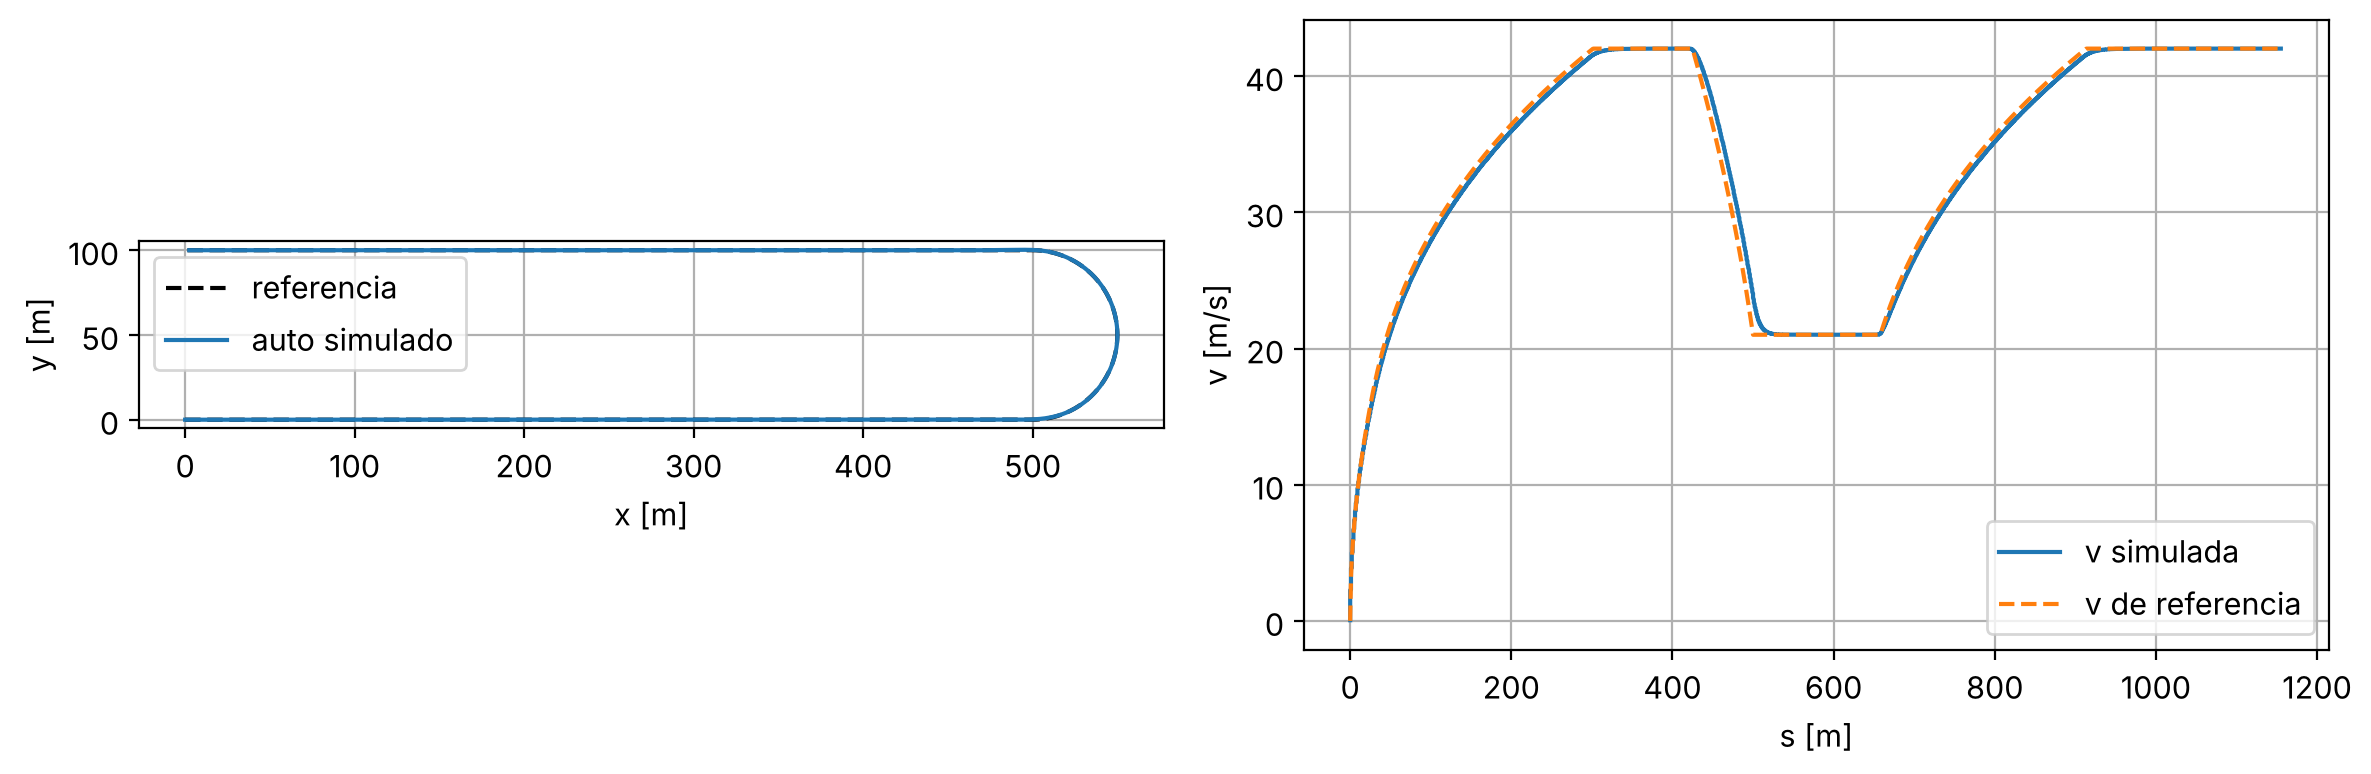

In [6]:
def simular(xr, yr, v_ref, p=P, dt=None, t_max=300.0):
    dt = dt or p["dt"]
    x, y = xr[0], yr[0]
    psi, v = np.arctan2(yr[1] - yr[0], xr[1] - xr[0]), v_ref[0]
    i_cerca, hist = 0, []
    for n in range(int(t_max / dt)):
        ventana = slice(i_cerca, min(i_cerca + 50, len(xr)))
        i_cerca += int(np.argmin((xr[ventana] - x)**2 + (yr[ventana] - y)**2))
        if i_cerca >= len(xr) - 2:
            break
        # control longitudinal: seguir v_ref respetando motor y frenos
        a_mot = min(p["a_acc_max"], p["P_util"] / (p["m"] * max(v, 1.0)))
        v_obj = v_ref[min(i_cerca + 3, len(v_ref) - 1)]          # velocidad pedida unos metros adelante
        a = np.clip((v_obj - v) / 0.3, -p["a_fre_max"], a_mot)
        # control lateral: pure pursuit
        Ld = max(5.0, 0.5 * v)
        j = min(i_cerca + int(Ld / p["ds"]), len(xr) - 1)
        alfa = np.arctan2(yr[j] - y, xr[j] - x) - psi
        delta = np.arctan2(2 * p["L"] * np.sin(alfa), Ld)
        # Euler semi-implícito (modelo de bicicleta)
        v = max(v + a * dt, 0.0)
        psi += v / p["L"] * np.tan(delta) * dt
        x += v * np.cos(psi) * dt
        y += v * np.sin(psi) * dt
        a_lat = v**2 * np.tan(delta) / p["L"]
        hist.append((n * dt, x, y, psi, v, a, a_lat, delta, i_cerca))
    cols = ["t", "x", "y", "psi", "v", "a", "a_lat", "delta", "i"]
    return {c: np.array(col) for c, col in zip(cols, zip(*hist))}

sim = simular(xc, yc, v_con_vis)
exceso = np.hypot(sim["a"], sim["a_lat"]) > P["mu"] * G * 1.05
print(f"Tiempo simulado: {sim['t'][-1]:.2f} s  |  tiempo del perfil: {tiempo_recorrido(v_con_vis):.2f} s")
print(f"Pasos que superan el círculo de fricción (5 % de tolerancia): {exceso.mean()*100:.1f} %")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(xc, yc, "k--", label="referencia"); a1.plot(sim["x"], sim["y"], label="auto simulado")
a1.set_aspect("equal"); a1.set(xlabel="x [m]", ylabel="y [m]"); a1.legend()
a2.plot(s[sim["i"]], sim["v"], label="v simulada"); a2.plot(s, v_con_vis, "--", label="v de referencia")
a2.set(xlabel="s [m]", ylabel="v [m/s]"); a2.legend()
plt.tight_layout(); plt.show()

> ✍️ **Por escribir:** interpretar la diferencia entre el tiempo simulado y el del perfil, y si el auto respeta el círculo de fricción. Si no lo respeta, explicar por qué (el controlador reacciona con retraso).

### 3.5 Huella rectangular y salidas de pista

El modelo de bicicleta trata al auto como una línea. Para detectar salidas, ubicamos las cuatro esquinas de un rectángulo de $largo \times ancho$, girado según $\psi$:

$$\begin{pmatrix}x_e\\ y_e\end{pmatrix} = \begin{pmatrix}x\\ y\end{pmatrix} + \begin{pmatrix}\cos\psi & -\sin\psi\\ \sin\psi & \cos\psi\end{pmatrix}\begin{pmatrix}\pm largo/2\\ \pm ancho/2\end{pmatrix}$$

Una esquina está fuera de la pista si su distancia a la línea central supera la mitad del ancho de la pista.

In [7]:
def esquinas(x, y, psi, p=P):
    dx = np.array([1, 1, -1, -1]) * p["largo"] / 2
    dy = np.array([1, -1, -1, 1]) * p["ancho"] / 2
    c, s_ = np.cos(psi), np.sin(psi)
    return x + c * dx - s_ * dy, y + s_ * dx + c * dy

def salidas_de_pista(sim, xc, yc, p=P, cada=10):
    fuera = []
    for n in range(0, len(sim["t"]), cada):
        ex, ey = esquinas(sim["x"][n], sim["y"][n], sim["psi"][n], p)
        i = sim["i"][n]; w = slice(max(i - 60, 0), i + 60)
        d = np.sqrt(((xc[w][None, :] - ex[:, None])**2 + (yc[w][None, :] - ey[:, None])**2).min(axis=1))
        fuera.append(d.max() > p["ancho_pista"] / 2)
    return np.array(fuera)

fuera = salidas_de_pista(sim, xc, yc)
print(f"Instantes con alguna esquina fuera de la pista: {fuera.sum()} de {len(fuera)}")

Instantes con alguna esquina fuera de la pista: 0 de 387


> ✍️ **Por escribir:** interpretar (con la línea central y una pista de 11 m de ancho no debería haber salidas; con una trayectoria optimizada pegada al borde sí podría haberlas).

## 4. Validación

Comparamos la simulación con casos que tienen solución analítica. Si el código reproduce estos casos, confiamos más en él cuando no hay solución exacta (la pista completa).

### 4.1 Frenado en recta y convergencia con $\Delta t$

Frenamos desde $v_0 = 30$ m/s con desaceleración constante $a_f$ y medimos la distancia recorrida hasta detenerse. La solución exacta es $d = v_0^2/(2a_f)$. Repetimos con varios $\Delta t$ para ver cómo cambia el error.

dt =  0.200 s  ->  error =  2.9982 m  (5.882 %)
dt =  0.100 s  ->  error =  1.4991 m  (2.941 %)
dt =  0.050 s  ->  error =  0.7496 m  (1.471 %)
dt =  0.020 s  ->  error =  0.2998 m  (0.588 %)
dt =  0.010 s  ->  error =  0.1499 m  (0.294 %)
dt =  0.005 s  ->  error =  0.0750 m  (0.147 %)
dt =  0.001 s  ->  error =  0.0150 m  (0.029 %)


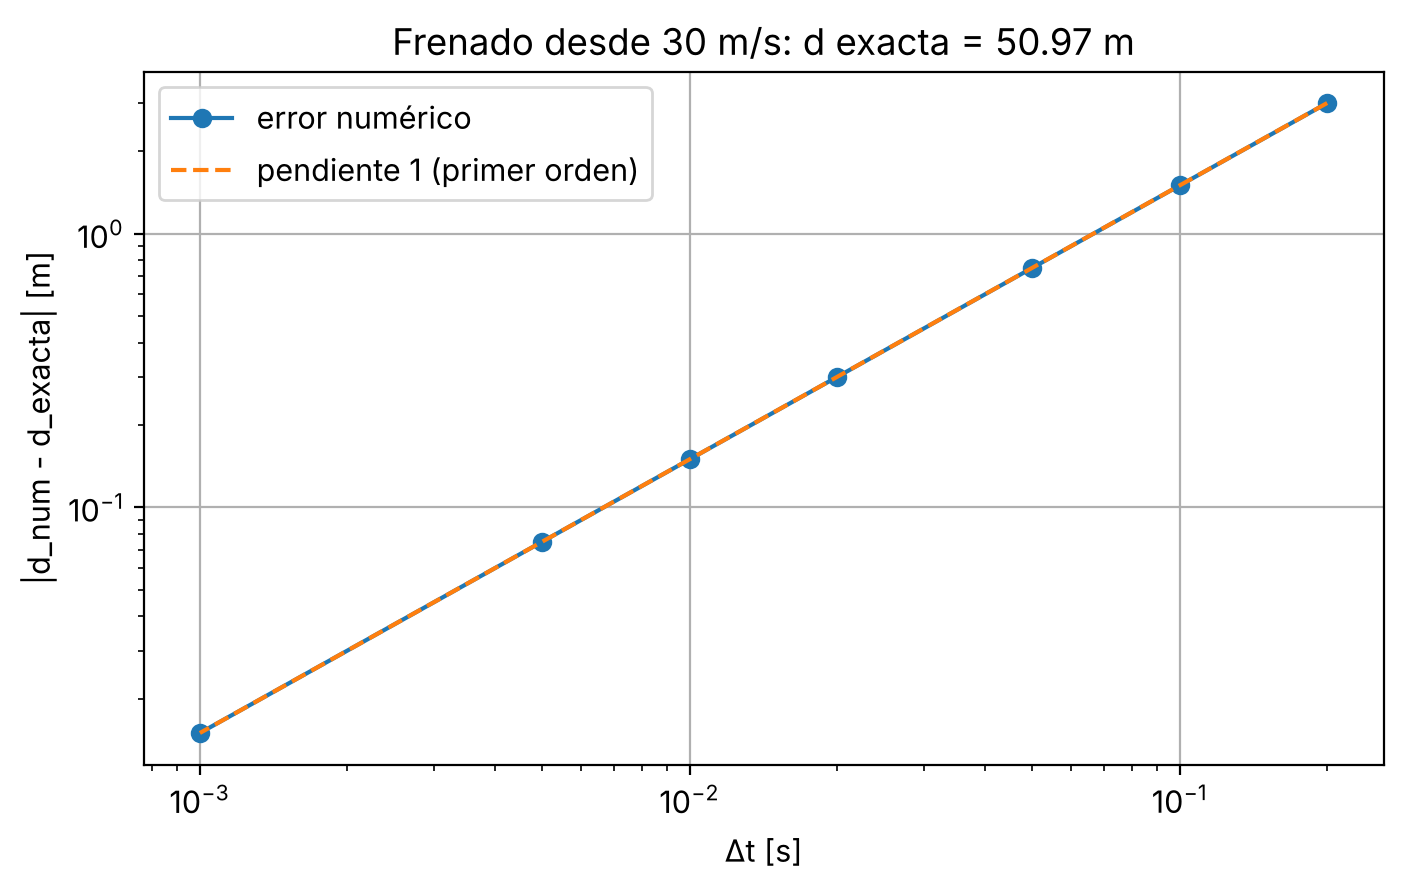

In [8]:
def frenar_recta(v0, a_f, dt):
    x, v = 0.0, v0
    while v > 0:
        v = max(v - a_f * dt, 0.0)   # Euler semi-implícito
        x += v * dt
    return x

v0, a_f = 30.0, P["a_fre_max"]
d_exacta = distancia_frenado(v0, 0.0, a_f)
dts = np.array([0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001])
errores = np.array([abs(frenar_recta(v0, a_f, dt) - d_exacta) for dt in dts])

for dt, e in zip(dts, errores):
    print(f"dt = {dt:6.3f} s  ->  error = {e:7.4f} m  ({100*e/d_exacta:.3f} %)")

plt.loglog(dts, errores, "o-", label="error numérico")
plt.loglog(dts, errores[-1] * dts / dts[-1], "--", label="pendiente 1 (primer orden)")
plt.xlabel("Δt [s]"); plt.ylabel("|d_num - d_exacta| [m]"); plt.title(f"Frenado desde {v0:.0f} m/s: d exacta = {d_exacta:.2f} m")
plt.legend(); plt.show()

> ✍️ **Por escribir:** interpretar la pendiente (el error baja proporcional a $\Delta t$: método de primer orden) y justificar el $\Delta t$ elegido. Pregunta típica: *"Predigan qué pasa si duplicamos el paso de tiempo"* → el error se duplica aproximadamente.

### 4.2 Aceleración con potencia constante

Si el motor entrega potencia constante $P$ (y no hay otros límites), la energía cinética crece linealmente: $\frac{1}{2}mv^2 = \frac{1}{2}mv_0^2 + Pt$, de donde

$$v(t) = \sqrt{v_0^2 + \frac{2Pt}{m}}$$

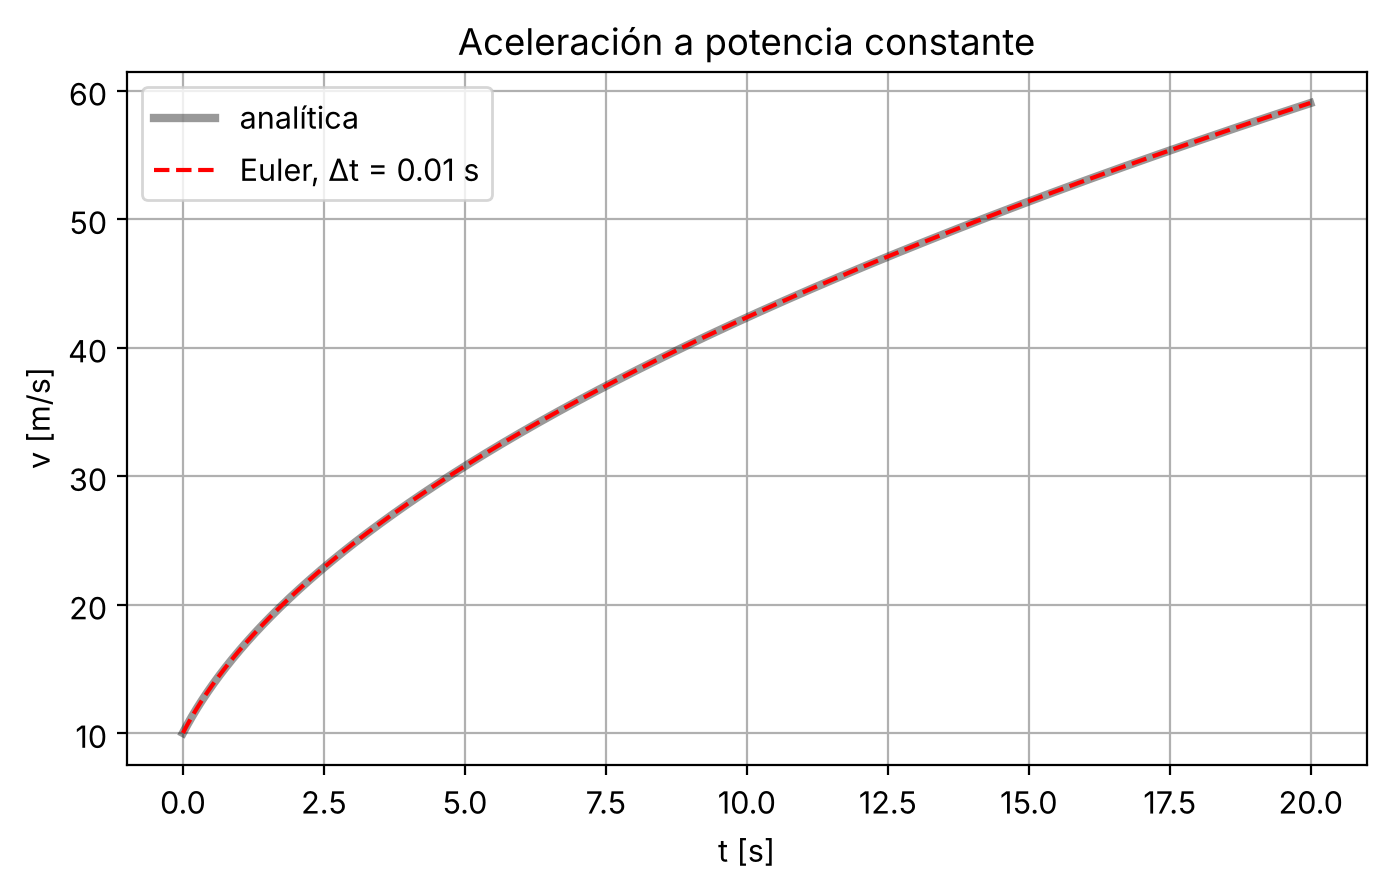

Error relativo máximo: 0.078 %


In [9]:
v0, T, dt = 10.0, 20.0, P["dt"]
t = np.arange(0, T, dt)
v_num = np.empty_like(t); v_num[0] = v0
for n in range(len(t) - 1):
    v_num[n + 1] = v_num[n] + P["P_util"] / (P["m"] * v_num[n]) * dt
v_exacta = np.sqrt(v0**2 + 2 * P["P_util"] * t / P["m"])

plt.plot(t, v_exacta, "k-", lw=3, alpha=0.4, label="analítica")
plt.plot(t, v_num, "r--", label=f"Euler, Δt = {dt} s")
plt.xlabel("t [s]"); plt.ylabel("v [m/s]"); plt.title("Aceleración a potencia constante"); plt.legend(); plt.show()
print(f"Error relativo máximo: {np.max(np.abs(v_num - v_exacta) / v_exacta)*100:.3f} %")

> ✍️ **Por escribir:** interpretar (la aceleración cae con la velocidad porque $a = P/(mv)$).

### 4.3 Giro con ángulo constante

Con $\delta$ constante, el modelo de bicicleta debe describir un círculo de radio $R = L/\tan\delta$. Además, si $v > \sqrt{\mu g R}$ la maniobra supera el agarre y el modelo debe marcarla como inviable.

In [10]:
def circulo_bicicleta(R_obj, v, dt=P["dt"], T=20.0, p=P):
    delta = np.arctan(p["L"] / R_obj)
    x, y, psi, xs, ys = 0.0, 0.0, 0.0, [], []
    for _ in range(int(T / dt)):
        psi += v / p["L"] * np.tan(delta) * dt
        x += v * np.cos(psi) * dt; y += v * np.sin(psi) * dt
        xs.append(x); ys.append(y)
    xs, ys = np.array(xs), np.array(ys)
    # radio medido: ajuste de un círculo x² + y² + Dx + Ey + F = 0 por mínimos cuadrados
    D, E, F = np.linalg.lstsq(np.c_[xs, ys, np.ones_like(xs)], -(xs**2 + ys**2), rcond=None)[0]
    R_num = np.sqrt(D**2 / 4 + E**2 / 4 - F)
    return xs, ys, R_num, delta

R_obj = 50.0
for v in [15.0, v_max_curva(R_obj), 25.0]:
    xs, ys, R_num, delta = circulo_bicicleta(R_obj, v)
    viable = v**2 / R_obj <= P["mu"] * G
    print(f"v = {v:5.2f} m/s | R medido = {R_num:6.2f} m (objetivo {R_obj}) | δ = {np.degrees(delta):.2f}° "
          f"| volante = {np.degrees(delta)*P['r_dir']:.0f}° | a_lat = {v**2/R_obj:.2f} m/s² -> {'viable' if viable else 'INVIABLE'}")

v = 15.00 m/s | R medido =  50.00 m (objetivo 50.0) | δ = 2.98° | volante = 45° | a_lat = 4.50 m/s² -> viable
v = 21.01 m/s | R medido =  50.00 m (objetivo 50.0) | δ = 2.98° | volante = 45° | a_lat = 8.83 m/s² -> viable
v = 25.00 m/s | R medido =  50.00 m (objetivo 50.0) | δ = 2.98° | volante = 45° | a_lat = 12.50 m/s² -> INVIABLE


> ✍️ **Por escribir:** interpretar: el radio no depende de $v$ en el modelo cinemático (por eso necesitamos el límite de fricción aparte) y el caso de 25 m/s queda marcado como inviable.

> ✍️ **Por escribir:** **4.4 Validación con datos propios (opcional, se valora).** Medir en Assetto Corsa la distancia de frenado desde 100 km/h y la velocidad máxima sostenible en una curva de radio conocido, y compararlas con $v_0^2/(2a_f)$ y $\sqrt{\mu g R}$. Con esas dos medidas se calibran $a_f$ y $\mu$.

## 5. Visibilidad necesaria según $v_0$, $R$ y $\mu$

Usamos $D_{min} = (v_0^2 - \mu g R)/(2\mu g)$ para ver cómo cambia la distancia que el modelo necesita conocer hacia adelante. Después comprobamos el efecto de $D_v$ sobre el tiempo de recorrido en la pista de prueba.

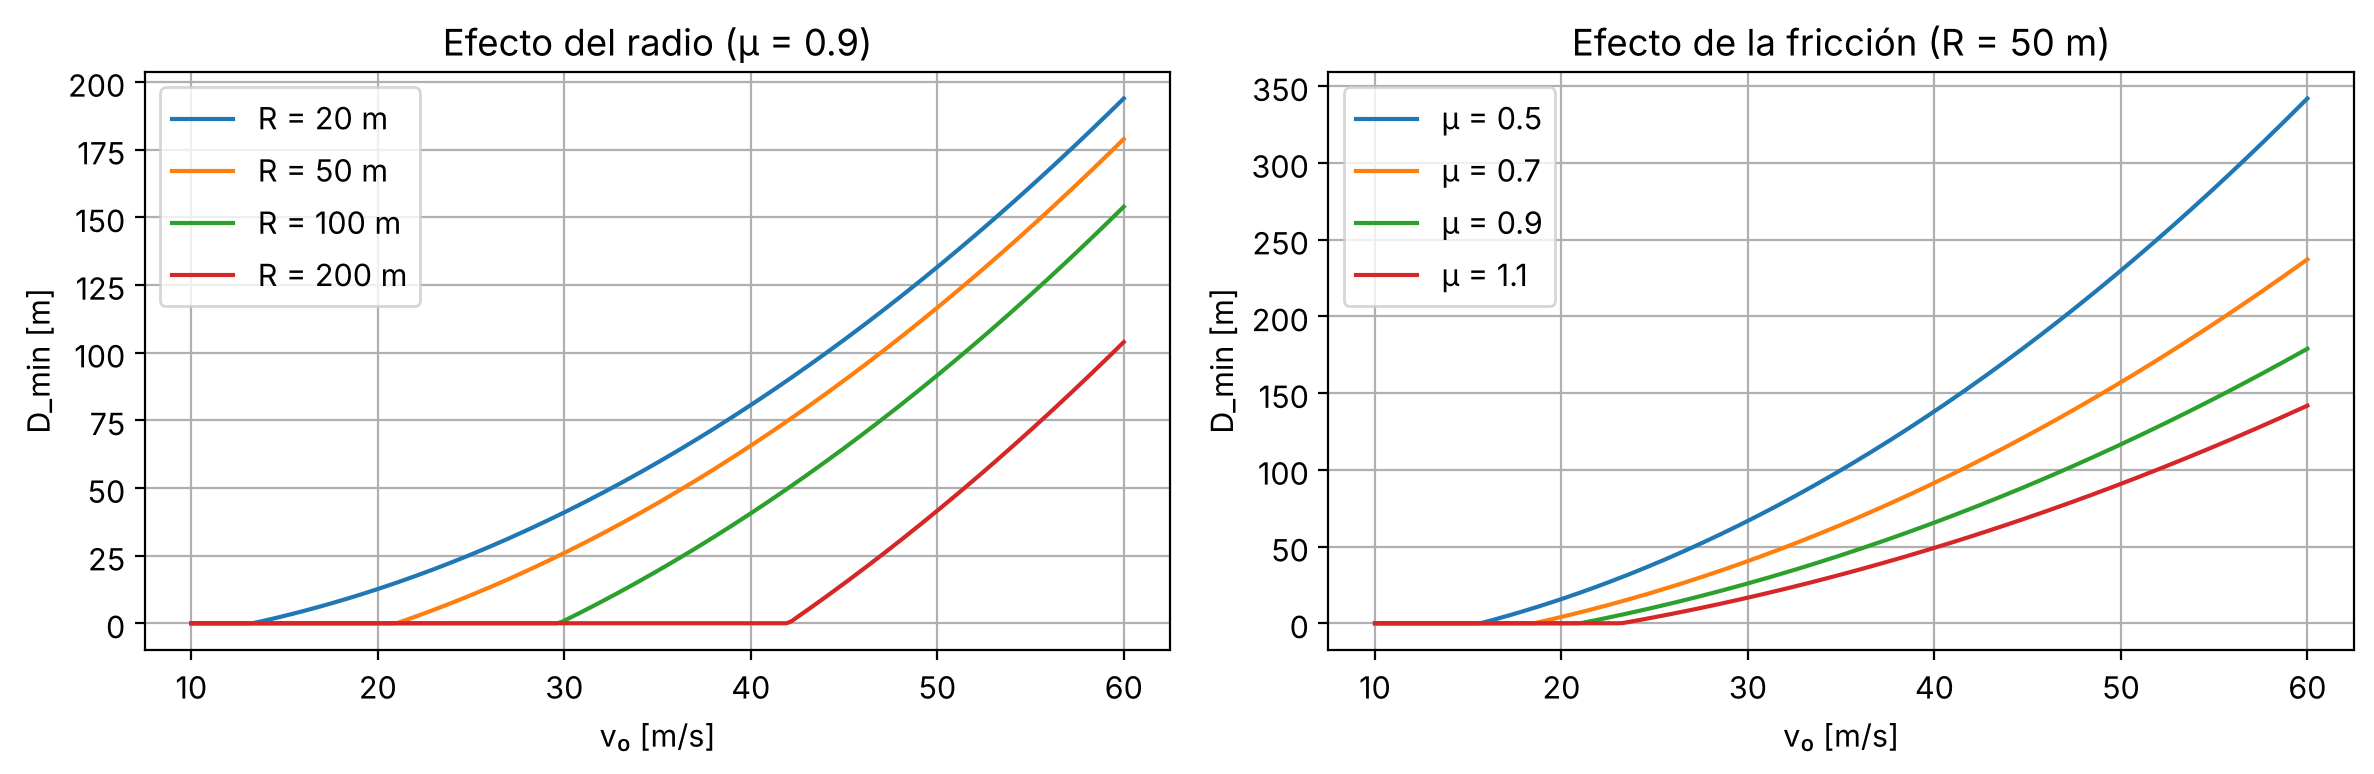

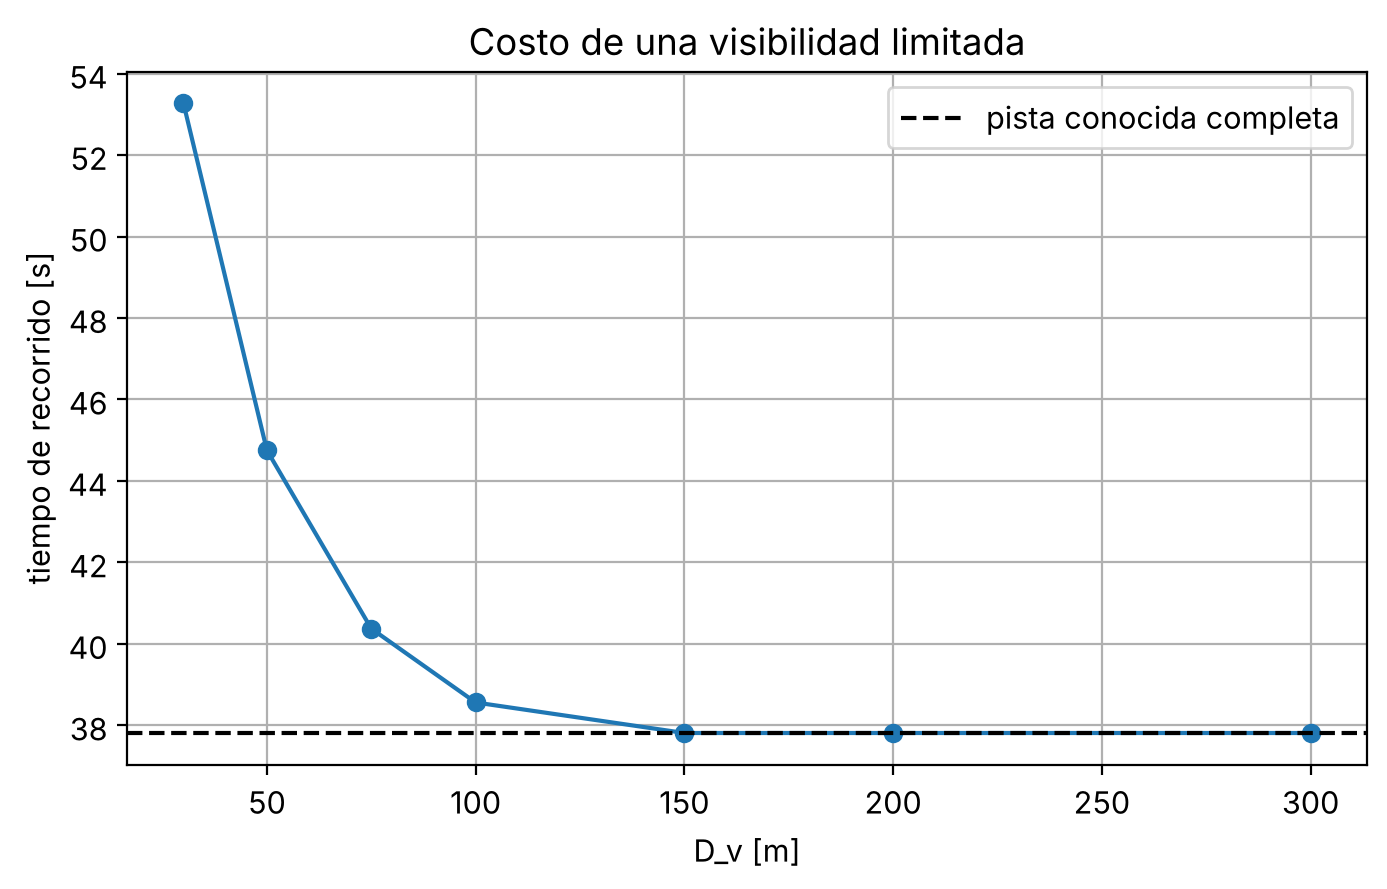

In [11]:
v0s = np.linspace(10, 60, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for R in [20, 50, 100, 200]:
    a1.plot(v0s, visibilidad_minima(v0s, R, P["mu"]), label=f"R = {R} m")
a1.set(xlabel="v₀ [m/s]", ylabel="D_min [m]", title=f"Efecto del radio (μ = {P['mu']})"); a1.legend()
for mu in [0.5, 0.7, 0.9, 1.1]:
    a2.plot(v0s, visibilidad_minima(v0s, 50, mu), label=f"μ = {mu}")
a2.set(xlabel="v₀ [m/s]", ylabel="D_min [m]", title="Efecto de la fricción (R = 50 m)"); a2.legend()
plt.tight_layout(); plt.show()

Dvs = np.array([30, 50, 75, 100, 150, 200, 300])
tiempos = [tiempo_recorrido(perfil_velocidad(kc, visibilidad=D)) for D in Dvs]
plt.plot(Dvs, tiempos, "o-"); plt.axhline(tiempo_recorrido(v_sin_vis), ls="--", c="k", label="pista conocida completa")
plt.xlabel("D_v [m]"); plt.ylabel("tiempo de recorrido [s]"); plt.title("Costo de una visibilidad limitada"); plt.legend(); plt.show()

> ✍️ **Por escribir:** responder la pregunta física con estas gráficas: cómo crece $D_{min}$ con $v_0$ (cuadrático), cómo baja con $R$ y con $\mu$, y a partir de qué $D_v$ ya no se gana tiempo.

## 6. Trayectoria optimizada frente a la línea central

Desplazamos lateralmente la línea central una distancia $n(s)$ en la dirección normal a la pista, sin salir del margen permitido:

$$|n(s)| \le \frac{ancho_{pista} - ancho_{auto}}{2} - margen$$

Definimos $n(s)$ con unos pocos puntos de control (cada 20 m) unidos por un spline cúbico, para que la trayectoria sea suave. Luego buscamos los desplazamientos que **minimizan el tiempo estimado** con el perfil de velocidad de la sección 3.3. No imponemos dónde va el *apex*: sale del cálculo.

Línea central: 38.51 s  |  optimizada: 38.01 s


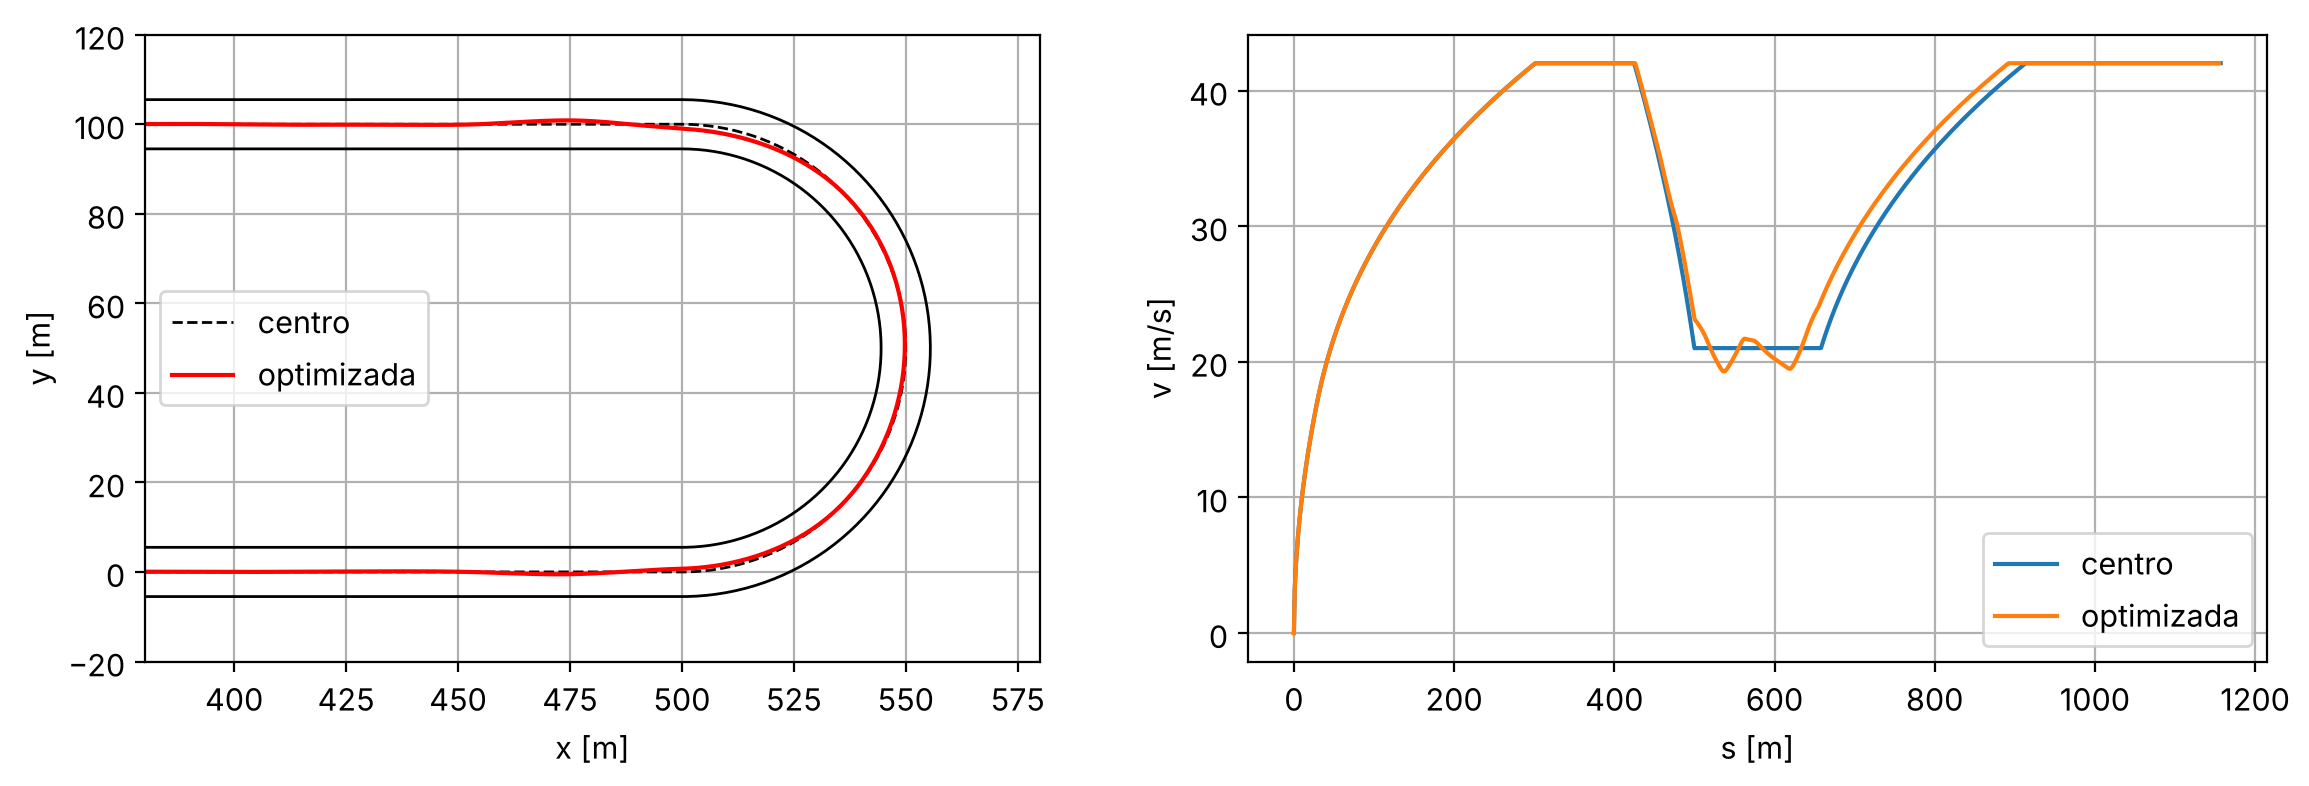

In [12]:
def normales(x, y):
    dx, dy = np.gradient(x), np.gradient(y)
    n = np.hypot(dx, dy)
    return -dy / n, dx / n

def trayectoria_desplazada(n_ctrl, xc, yc):
    s_ctrl = np.linspace(0, len(xc) - 1, len(n_ctrl))
    n = CubicSpline(s_ctrl, n_ctrl)(np.arange(len(xc)))
    nx, ny = normales(xc, yc)
    return remuestrear(xc + n * nx, yc + n * ny)

def tiempo_de(n_ctrl, xc, yc, p=P):
    x, y = trayectoria_desplazada(n_ctrl, xc, yc)
    return tiempo_recorrido(perfil_velocidad(curvatura(x, y), p, visibilidad=p["D_v"]))

n_max = (P["ancho_pista"] - P["ancho"]) / 2 - P["margen"]
n_ctrl0 = np.zeros(len(xc) // 20)
limites = [(0, 0)] + [(-n_max, n_max)] * (len(n_ctrl0) - 2) + [(0, 0)]
res = minimize(tiempo_de, n_ctrl0, args=(xc, yc), method="L-BFGS-B", bounds=limites, options={"maxiter": 60})

xo, yo = trayectoria_desplazada(res.x, xc, yc)
vo = perfil_velocidad(curvatura(xo, yo), visibilidad=P["D_v"])
print(f"Línea central: {tiempo_de(n_ctrl0, xc, yc):.2f} s  |  optimizada: {res.fun:.2f} s")

nx, ny = normales(xc, yc)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for signo in (1, -1):
    a1.plot(xc + signo * P["ancho_pista"] / 2 * nx, yc + signo * P["ancho_pista"] / 2 * ny, "k-", lw=1)
a1.plot(xc, yc, "k--", lw=1, label="centro"); a1.plot(xo, yo, "r-", label="optimizada")
a1.set_aspect("equal"); a1.set(xlabel="x [m]", ylabel="y [m]", xlim=(380, 580), ylim=(-20, 120)); a1.legend()
a2.plot(s, v_con_vis, label="centro"); a2.plot(np.arange(len(vo)) * P["ds"], vo, label="optimizada")
a2.set(xlabel="s [m]", ylabel="v [m/s]"); a2.legend()
plt.tight_layout(); plt.show()

> ✍️ **Por escribir:** interpretar si la trayectoria optimizada abre la curva (entrar por fuera, tocar el interior, salir por fuera) y cómo eso cambia el radio efectivo y la velocidad. Ojo: el optimizador encuentra un mínimo local con pocos puntos de control; vale la pena probar más puntos o más iteraciones. Comparar con la técnica de pilotaje que estudiaron.

## 7. Aplicación a Tocancipá

Cargamos la línea central de Tocancipá desde `datos/tocancipa_centro.csv` (columnas `x`, `y` en metros). Opciones para obtenerla: registrar la posición del auto con la telemetría de Assetto Corsa dando una vuelta lenta por el centro, o exportar la línea de IA que trae el mod. Si el archivo no existe, la celda usa la pista de prueba.

**Cuidado:** la curvatura calculada con puntos medidos sale ruidosa. Hay que suavizar la línea (por ejemplo con un promedio móvil o un spline) antes de calcular $\kappa$, y explicar esa decisión.

No se encontró datos/tocancipa_centro.csv: se usa la pista de prueba.
Tiempo estimado por la línea central: 38.56 s


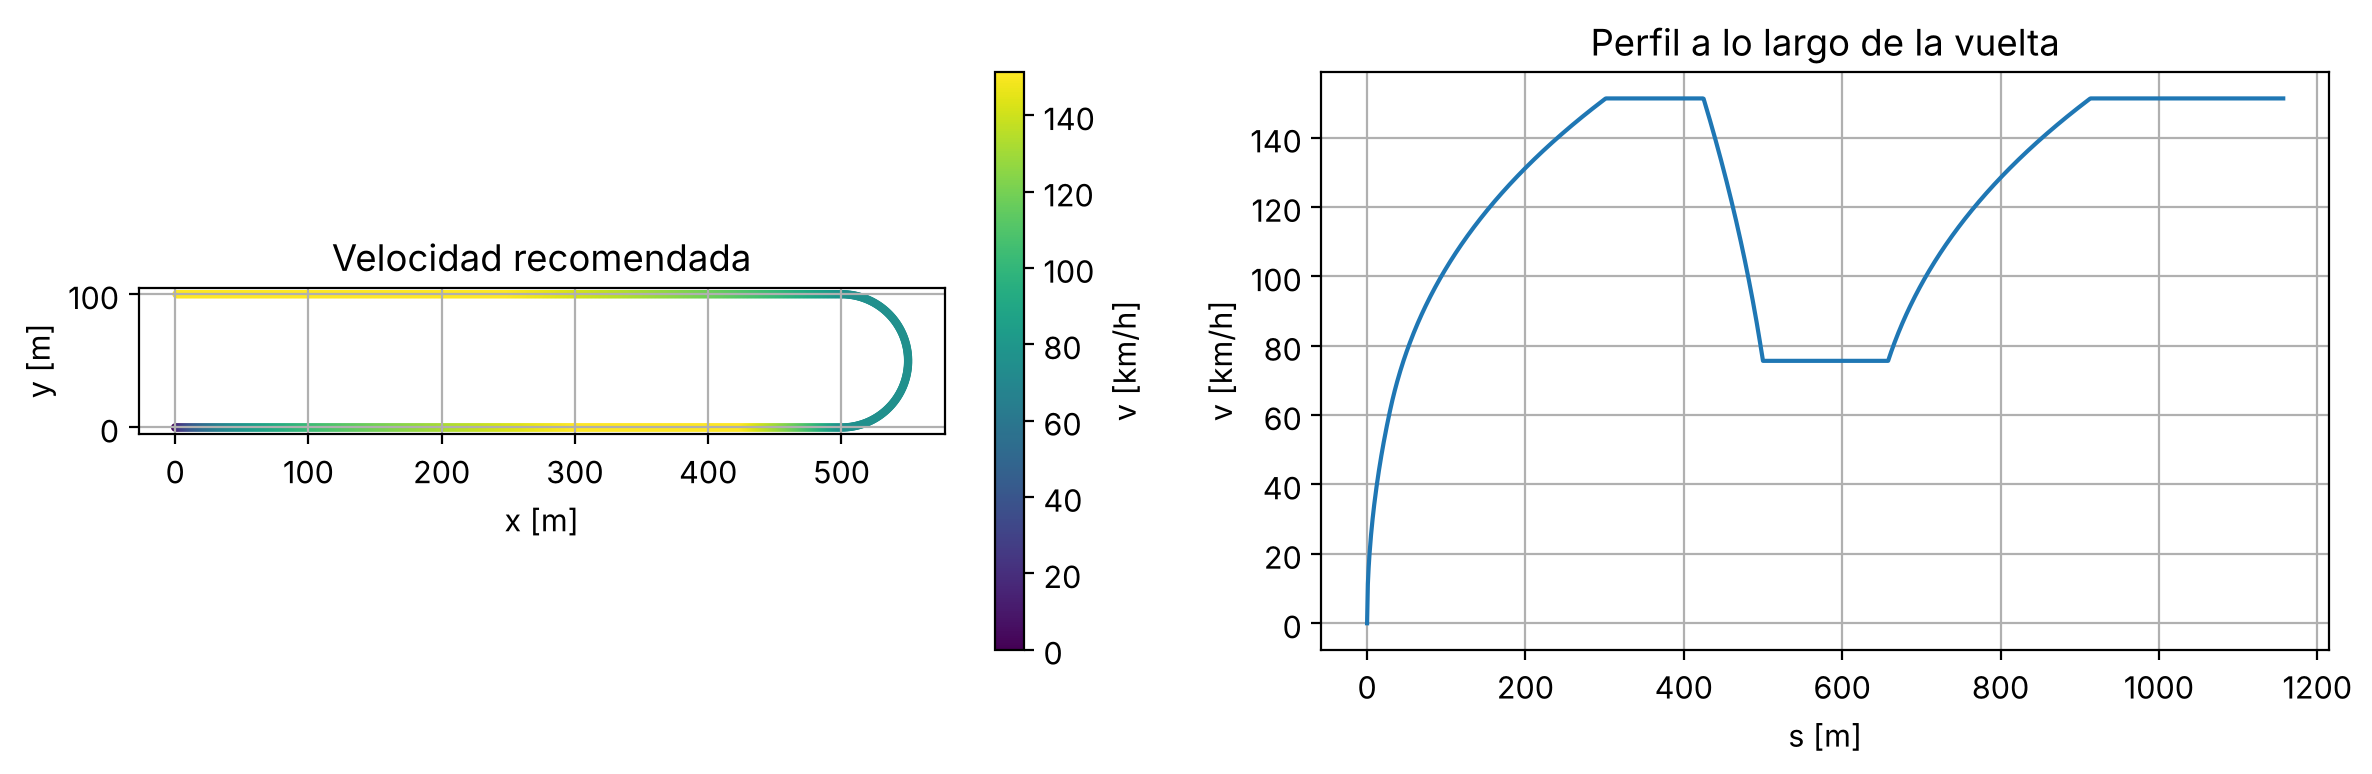

In [13]:
archivo = DATOS / "tocancipa_centro.csv"
if archivo.exists():
    datos = np.loadtxt(archivo, delimiter=",", skiprows=1)
    xt, yt = remuestrear(datos[:, 0], datos[:, 1])
    print(f"Tocancipá cargada: {len(xt)} puntos, {len(xt)*P['ds']/1000:.2f} km")
else:
    xt, yt = xc, yc
    print("No se encontró datos/tocancipa_centro.csv: se usa la pista de prueba.")

kt = curvatura(xt, yt)
vt = perfil_velocidad(kt, visibilidad=P["D_v"])
print(f"Tiempo estimado por la línea central: {tiempo_recorrido(vt):.2f} s")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
sc = a1.scatter(xt, yt, c=vt * 3.6, s=4, cmap="viridis"); plt.colorbar(sc, ax=a1, label="v [km/h]")
a1.set_aspect("equal"); a1.set(xlabel="x [m]", ylabel="y [m]", title="Velocidad recomendada")
a2.plot(np.arange(len(vt)) * P["ds"], vt * 3.6); a2.set(xlabel="s [m]", ylabel="v [km/h]", title="Perfil a lo largo de la vuelta")
plt.tight_layout(); plt.show()

> ✍️ **Por escribir:** interpretar en qué curvas de Tocancipá el modelo frena más, cuáles limita la visibilidad y repetir la optimización de la sección 6 sobre esta pista.

## 8. Comparación con Assetto Corsa y con el agente

El notebook no se conecta en vivo al simulador: compara con datos ya registrados, para que se ejecute sin el juego abierto.

**8.1 Previsto frente a observado.** Se carga `datos/telemetria_ac.csv` (columnas `s`, `v`: posición a lo largo de la pista en metros y velocidad en m/s) y se compara con el perfil del modelo.

In [14]:
archivo = DATOS / "telemetria_ac.csv"
if archivo.exists():
    tel = np.loadtxt(archivo, delimiter=",", skiprows=1)
    v_modelo = np.interp(tel[:, 0], np.arange(len(vt)) * P["ds"], vt)
    plt.plot(tel[:, 0], tel[:, 1] * 3.6, label="Assetto Corsa")
    plt.plot(tel[:, 0], v_modelo * 3.6, "--", label="modelo")
    plt.xlabel("s [m]"); plt.ylabel("v [km/h]"); plt.legend(); plt.show()
    print(f"Diferencia media: {np.mean(np.abs(tel[:, 1] - v_modelo))*3.6:.1f} km/h")
else:
    print("No se encontró datos/telemetria_ac.csv: completar cuando tengan telemetría.")

No se encontró datos/telemetria_ac.csv: completar cuando tengan telemetría.


> ✍️ **Por escribir:** **8.2 Resultados de las vueltas.** Tabla con: vueltas completadas / intentadas, tiempo medio y mejor tiempo, salidas de pista y colisiones, para cada condición:

| Condición | Vueltas válidas | Mejor tiempo | Tiempo medio | Salidas | Colisiones |
|---|---|---|---|---|---|
| Agente sin modelo | | | | | |
| Agente + línea central | | | | | |
| Agente + trayectoria optimizada | | | | | |
| Integrante 1 / 2 / 3 | | | | | |
| Referencia de YouTube (solo contexto) | | | | | |

Interpretar según los criterios de éxito: prueba básica, consistencia, desempeño competitivo, desempeño de alto nivel y aporte de la optimización.

> ✍️ **Por escribir:** **8.3 Función de recompensa.** Escribir la función usada para entrenar o refinar al agente (penalización por segundo, penalización progresiva cerca del borde según las dimensiones del auto, penalización mayor por salida o colisión, recompensa por completar la vuelta) y explicar por qué el agente no gana terminando antes con un choque.

> ✍️ **Por escribir:** 
## 9. Limitaciones

- Qué tan confiable es el modelo: dónde coincide con Assetto Corsa y dónde no, y qué fenómeno omitido (sección 2.4) explica cada diferencia.
- Cómo cambian los resultados con $\Delta t$ (sección 4.1) y con los parámetros $\mu$, $a_f$, $D_v$ (sección 5).
- Límites del modelo cinemático cerca del agarre máximo, de la pista hecha por la comunidad y de comparar con un simulador en vez de un auto real.

> ✍️ **Por escribir:** 
## 10. Conclusiones

Responder directamente la pregunta de investigación: ¿hasta qué punto el modelo reducido basta para que el agente complete vueltas rápidas y válidas? Resumir la respuesta a la pregunta física ($D_{min}$ frente a $v_0$, $R$, $\mu$) y el aporte de la trayectoria optimizada.

> ✍️ **Por escribir:** 
## 11. Declaración de uso de IA

Obligatoria (si falta: −5 puntos). Indicar qué herramientas se usaron y para qué. Ejemplo de formato:

| Herramienta | Uso |
|---|---|
| Claude (Anthropic) | Redacción de las explicaciones de los aspectos, simplificaciones y fenómenos omitidos; estructura inicial del notebook y código base de las secciones 3 a 6, revisado y modificado por el grupo. |
| … | … |

Recordar que todo lo que esté en el notebook puede ser objeto de preguntas en la sustentación.

## 12. Referencias

- Kunos Simulazioni. *Assetto Corsa* (2014). Página en Steam.
- Autódromo de Tocancipá 2.0, mod para Assetto Corsa (APVS), en Overtake.gg.
- *A Simulation Benchmark for Autonomous Racing* (Assetto Corsa Gym), arXiv:2407.16680 (2024).
- ✍️ Agregar: texto del curso, fuente de los datos del auto y el video de referencia de YouTube.